# Artificial Intelligence Assignment 1
## Customer Churn Prediction Using Machine Learning

This notebook implements the complete machine-learning pipeline required by the assignment: data loading, understanding, preprocessing, EDA, feature engineering/encoding, train/test split, multiple classification models, evaluation, comparison, and sample customer prediction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

pd.set_option('display.max_columns', None)
DATA_PATH = r'/mnt/data/WA_Fn-UseC_-Telco-Customer-Churn (1).csv'
df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully.')
print('Shape:', df.shape)
df.head()

Dataset loaded successfully.
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1. Data Loading and Understanding
The target variable is **Churn**. `Yes` means the customer left the company, while `No` means the customer remained. Important fields include `tenure` (months as a customer), `Contract` (contract type), `InternetService`, `MonthlyCharges`, `TotalCharges`, support/security services, and payment method.

In [2]:
print('Columns:')
print(df.columns.tolist())
print('\nData types:')
print(df.dtypes)
print('\nBasic statistics:')
display(df.describe(include='all').T)
print('\nTarget distribution:')
print(df['Churn'].value_counts())

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Basic statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### 2. Data Preprocessing
We check missing values, duplicates, data types, and identifiers. `TotalCharges` looks numeric but is stored as text because some rows contain blank strings. These blanks are converted to missing values and then removed because there are only 11 of them. `customerID` is dropped because it uniquely identifies a customer and should not be used as a behavioral predictor.

In [3]:
print('Missing values before conversion:')
print(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Blank TotalCharges values:', (df['TotalCharges'].astype(str).str.strip() == '').sum())

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges after numeric conversion:', df['TotalCharges'].isna().sum())

df = df.dropna(subset=['TotalCharges']).copy()
df = df.drop(columns=['customerID'])
print('Cleaned shape:', df.shape)
print('Total remaining missing values:', df.isna().sum().sum())
print('Duplicate rows after cleaning:', df.duplicated().sum())

Missing values before conversion:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate rows: 0
Blank TotalCharges values: 11
Missing TotalCharges after numeric conversion: 11
Cleaned shape: (7032, 20)
Total remaining missing values: 0
Duplicate rows after cleaning: 22


### 3. Exploratory Data Analysis
The following charts examine churn distribution and relationships with contract type, tenure, internet service, and monthly charges.

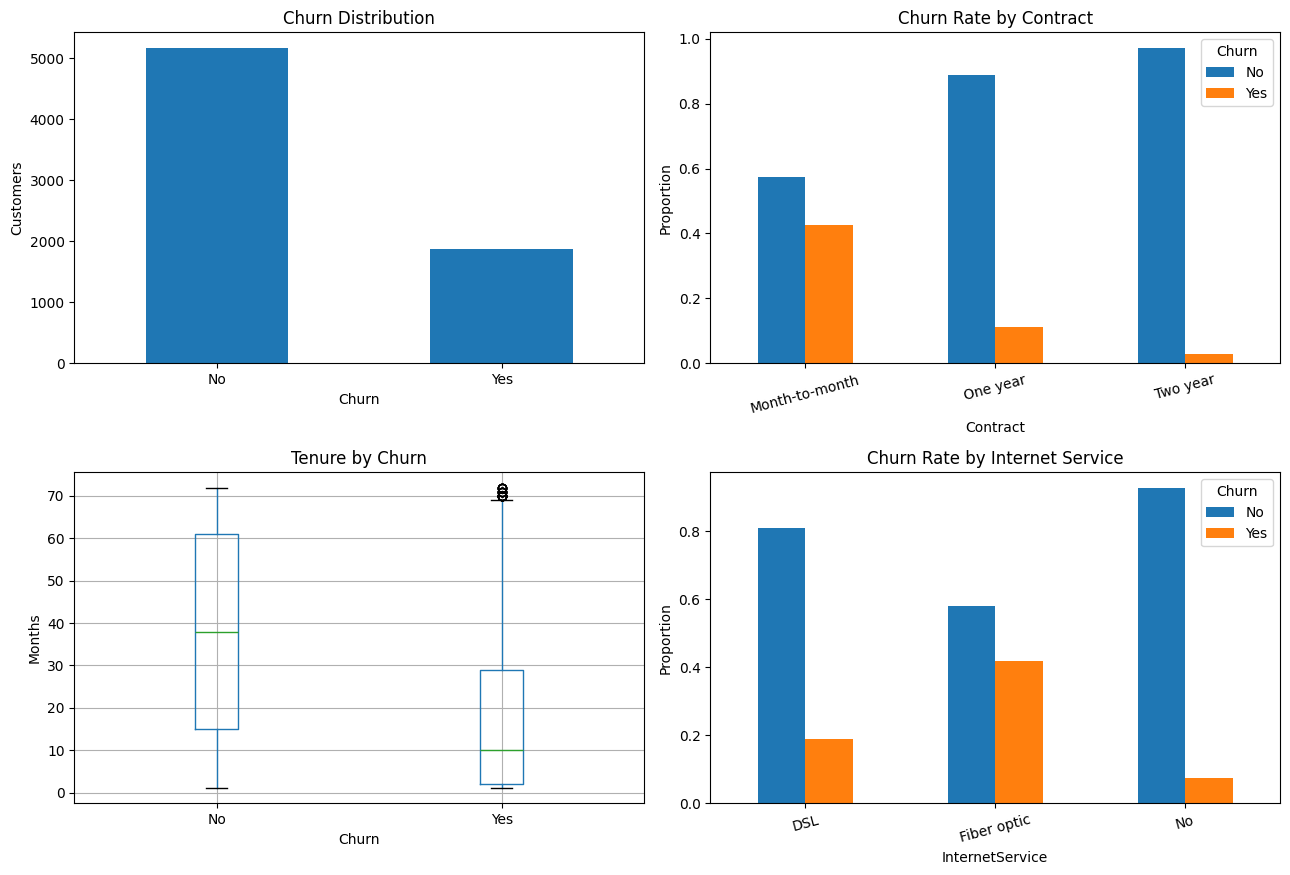

Overall churn rate: 26.58%

Churn rate by contract (%):
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Yes, dtype: float64

Average tenure by churn:
Churn
No     37.65
Yes    17.98
Name: tenure, dtype: float64

Average monthly charges by churn:
Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

df['Churn'].value_counts().plot(kind='bar', ax=axes[0,0], title='Churn Distribution')
axes[0,0].set_xlabel('Churn'); axes[0,0].set_ylabel('Customers'); axes[0,0].tick_params(axis='x', rotation=0)

pd.crosstab(df['Contract'], df['Churn'], normalize='index').plot(kind='bar', ax=axes[0,1], title='Churn Rate by Contract')
axes[0,1].set_ylabel('Proportion'); axes[0,1].tick_params(axis='x', rotation=15)

df.boxplot(column='tenure', by='Churn', ax=axes[1,0])
axes[1,0].set_title('Tenure by Churn'); axes[1,0].set_xlabel('Churn'); axes[1,0].set_ylabel('Months')

pd.crosstab(df['InternetService'], df['Churn'], normalize='index').plot(kind='bar', ax=axes[1,1], title='Churn Rate by Internet Service')
axes[1,1].set_ylabel('Proportion'); axes[1,1].tick_params(axis='x', rotation=15)
plt.suptitle('')
plt.tight_layout()
plt.savefig('/mnt/data/churn_eda.png', dpi=160, bbox_inches='tight')
plt.show()

print('Overall churn rate: %.2f%%' % ((df['Churn']=='Yes').mean()*100))
print('\nChurn rate by contract (%):')
print((pd.crosstab(df['Contract'], df['Churn'], normalize='index')['Yes']*100).round(2))
print('\nAverage tenure by churn:')
print(df.groupby('Churn')['tenure'].mean().round(2))
print('\nAverage monthly charges by churn:')
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

### 4. Feature Engineering and Encoding
`X` contains the customer input features and `y` is the target. Categorical variables are one-hot encoded. Numeric variables are standardized for Logistic Regression. The transformations are placed inside a pipeline so the same preprocessing is applied consistently during training and prediction.

In [5]:
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print('X shape:', X.shape)
print('y shape:', y.shape)
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
])

X shape: (7032, 19)
y shape: (7032,)
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 5. Training and Testing
The cleaned data is split into 80% training and 20% testing data. `stratify=y` keeps approximately the same churn proportion in both sets. Three classifiers are trained: Logistic Regression, Decision Tree, and Random Forest.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Training set:', X_train.shape, 'Testing set:', X_test.shape)
print('Training churn rate:', round(y_train.mean(), 4))
print('Testing churn rate:', round(y_test.mean(), 4))

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight=None),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
}

trained = {}
results = []
for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained[name] = pipe
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred)
    })
results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
display(results_df.round(4))

Training set: (5625, 19) Testing set: (1407, 19)
Training churn rate: 0.2658
Testing churn rate: 0.2658


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8038,0.6485,0.5722,0.6080
1,Decision Tree,0.7910,0.6176,0.5615,0.5882
2,Random Forest,0.7918,0.6373,0.5027,0.5620


### 6. Model Evaluation
Accuracy measures total correct predictions. Precision measures how many predicted churners actually churned. Recall measures how many real churners were detected. F1-score balances precision and recall. Because churn is less common than non-churn, these additional metrics are important.

Selected final model by highest test F1-score: Logistic Regression


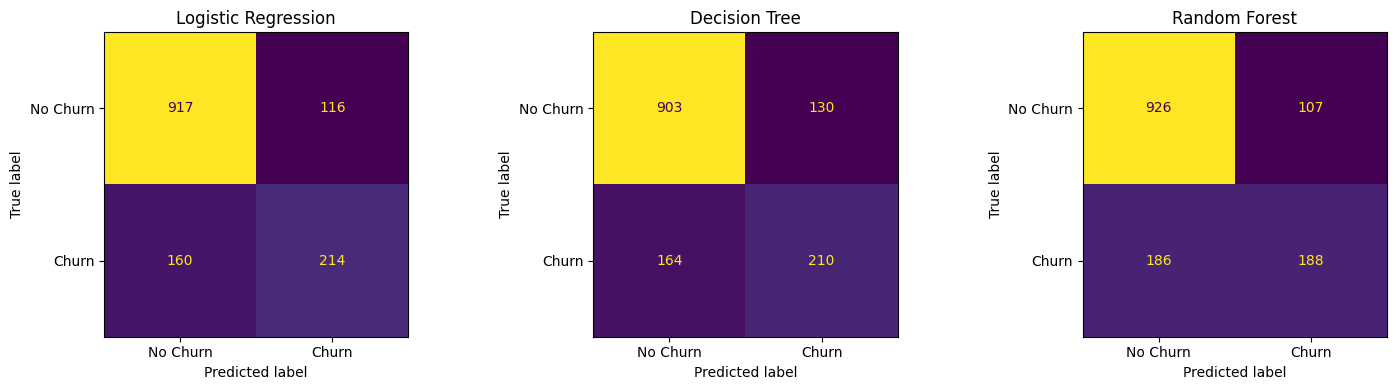


--- Logistic Regression ---
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


--- Decision Tree ---
              precision    recall  f1-score   support

    No Churn       0.85      0.87      0.86      1033
       Churn       0.62      0.56      0.59       374

    accuracy                           0.79      1407
   macro avg       0.73      0.72      0.72      1407
weighted avg       0.79      0.79      0.79      1407


--- Random Forest ---
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1033
       Churn       0.64      0.50      0.56       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407

In [7]:
best_name = results_df.iloc[0]['Model']
best_model = trained[best_name]
print('Selected final model by highest test F1-score:', best_name)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, trained.items()):
    pred = pipe.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['No Churn','Churn'], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig('/mnt/data/confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()

for name, pipe in trained.items():
    pred = pipe.predict(X_test)
    print('\n---', name, '---')
    print(classification_report(y_test, pred, target_names=['No Churn','Churn']))

### 7. Application / Prediction
A sample customer's information is passed to the final pipeline. The pipeline automatically applies the same preprocessing and then predicts `Churn` or `No Churn`.

In [8]:
sample_customer = pd.DataFrame([{
    'gender':'Female', 'SeniorCitizen':0, 'Partner':'No', 'Dependents':'No',
    'tenure':3, 'PhoneService':'Yes', 'MultipleLines':'No',
    'InternetService':'Fiber optic', 'OnlineSecurity':'No', 'OnlineBackup':'No',
    'DeviceProtection':'No', 'TechSupport':'No', 'StreamingTV':'Yes',
    'StreamingMovies':'Yes', 'Contract':'Month-to-month', 'PaperlessBilling':'Yes',
    'PaymentMethod':'Electronic check', 'MonthlyCharges':95.0, 'TotalCharges':285.0
}])

prediction = best_model.predict(sample_customer)[0]
probability = best_model.predict_proba(sample_customer)[0,1] if hasattr(best_model.named_steps['model'], 'predict_proba') else None
print('Final model:', best_name)
print('Prediction:', 'Churn' if prediction == 1 else 'No Churn')
if probability is not None:
    print('Estimated churn probability: %.2f%%' % (probability*100))
display(sample_customer)

Final model: Logistic Regression
Prediction: Churn
Estimated churn probability: 75.67%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,3,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.0,285.0


### Conclusion
The project built an end-to-end churn prediction system using the supplied telecom dataset. Data quality issues were corrected, customer behavior was explored, categorical features were encoded, and multiple classification models were trained and evaluated. The final model is selected from the tested models using F1-score so that performance on the minority churn class is considered rather than relying only on accuracy.

**Limitations:** the model learns only from the supplied historical fields; the classes are imbalanced; relationships may change over time; and a prediction is not a certainty. A telecom company could use churn probabilities to identify customers for retention offers, support outreach, or service improvements, while monitoring model performance and avoiding inappropriate automated decisions.